# fdia-graph in five cells

Generate a small attacked timeline on the IEEE-14 grid, load it, and look at the attack in it.
It takes about a minute.

```
pip install "fdia-graph[generate]" matplotlib
```

## 1. Generate

600 frames of meter readings with one overload attack (`Am`) placed in them. With the same seed a rerun places the same attack. The first run downloads the IEEE-14 operating points, and the timeline is registered as `demo` in the local cache.

In [1]:
import fdia_graph as fg

fg.generate("ieee14", name="demo", frames=600, seed=123, families=("Am",), attacked_frac=0.2)
ds = fg.load("demo", order="time")
ds.summary()

Summary(system=14, N=14, E=20, n=600, families={'benign': 540, 'Am': 60})

## 2. What a model gets

One row per frame: the readings at every bus and branch, and a label per bus. `edge_index` lists each branch's two ends once.

In [2]:
arrays = ds.export(["node_x", "edge_x", "y", "family"])
for name, a in arrays.items():
    print(f"{name:8} {a.shape}")

edge_index (2, 20)
node_x   (600, 14, 4)
edge_x   (600, 20, 2)
y        (600, 14)
family   (600,)


## 3. Where the attack is

The episode table says when the attack runs and which buses it labels. Buses are positions, counted from zero.

In [3]:
ep = ds.episodes
onset, length = int(ep.onset[0]), int(ep.length[0])
buses = [int(b) for b in ep.buses[0]]
print(f"frames {onset} to {onset + length - 1}, labelled buses {buses}")
print("attacked buses per frame, around the start:", arrays["y"][onset - 2 : onset + 3].sum(axis=1))

frames 92 to 151, labelled buses [9, 13]
attacked buses per frame, around the start: [0 0 2 2 2]


## 4. What the attack does

The file keeps, beside the readings, what each meter would have read without the attack. Their difference at the last attacked frame shows which buses' injection readings moved.

Five buses move and two are labelled. The labelled two are where the attacker pretends a load change. The other three are one branch away: their voltages stay true, and their injection readings take up the change.

In [4]:
import h5py
import numpy as np

from fdia_graph.constants.channels import NodeChannel

P = NodeChannel.P_INJ  # the active-injection column of the bus readings
last = onset + length - 1
with h5py.File(ds.path, "r") as f:
    moved = f["data/node_x"][last, :, P] - f["benign/node_benign"][last, :, P]
    lines = f["episodes/am_line"][:].astype(int)
    ratings = f["episodes/am_rating_mva"][:]
    window = slice(onset - 40, last + 41)
    reported = np.hypot(*np.moveaxis(f["data/edge_x"][window][:, lines], -1, 0))
    without = np.hypot(*np.moveaxis(f["benign/edge_benign"][window][:, lines], -1, 0))
for bus in np.flatnonzero(np.abs(moved) > 1e-9):
    print(f"bus {bus}: reported active injection moved by {moved[bus]:+.2f} MW")

bus 8: reported active injection moved by -5.03 MW
bus 9: reported active injection moved by +3.20 MW
bus 10: reported active injection moved by -0.99 MW
bus 12: reported active injection moved by -2.16 MW
bus 13: reported active injection moved by +4.86 MW


## 5. What an operator would see

The flow two branches report, against the flow without the attack. The dashed line is each branch's rating.

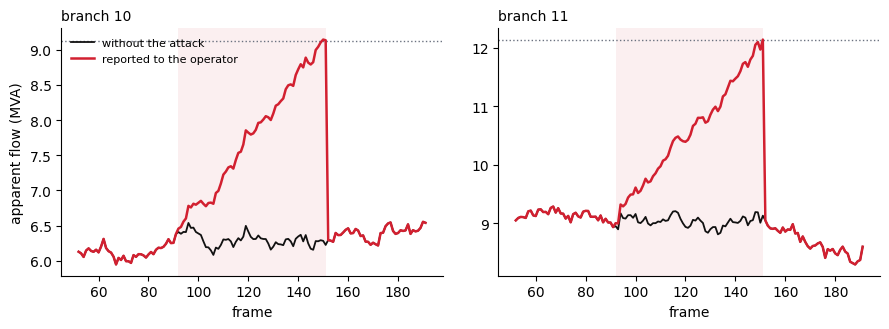

In [5]:
import matplotlib.pyplot as plt

t = np.arange(window.start, window.stop)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for k, ax in enumerate(axes):
    ax.axvspan(onset, last, color="#D22030", alpha=0.07, lw=0)
    ax.axhline(ratings[k], color="#6b7280", lw=1, ls=":")
    ax.plot(t, without[:, k], color="#111111", lw=1.3, label="without the attack")
    ax.plot(t, reported[:, k], color="#D22030", lw=1.8, label="reported to the operator")
    ax.set_title(f"branch {int(lines[k])}", loc="left", fontsize=10)
    ax.set_xlabel("frame")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("apparent flow (MVA)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## Where next

- `docs/guides/tour.md` follows this same attack through the code, step by step.
- `docs/getting-started/analyse.md` runs a state estimator on a timeline.
- `fg.load("ieee118", split="train")` downloads a released timeline of 72,000 frames.